In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

In [4]:
metric_outputs = [
    'picp-lstm-ev.csv',
    'picp-lstm-yp3.csv',
    'picp-qrf-ev.csv',
    'picp-qrf-yp3.csv',
    'picp-xgb-ev.csv',
    'picp-xgb-yp3.csv',
    'pinaw-lstm-ev.csv',
    'pinaw-lstm-yp3.csv',
    'pinaw-qrf-ev.csv',
    'pinaw-qrf-yp3.csv',
    'pinaw-xgb-ev.csv',
    'pinaw-xgb-yp3.csv',
    'loss_low-lstm-ev.csv',
    'loss_low-lstm-yp3.csv',
    'loss_low-qrf-ev.csv',
    'loss_low-qrf-yp3.csv',
    'loss_low-xgb-ev.csv',
    'loss_low-xgb-yp3.csv',
    'loss_high-lstm-ev.csv',
    'loss_high-lstm-yp3.csv',
    'loss_high-qrf-ev.csv',
    'loss_high-qrf-yp3.csv',
    'loss_high-xgb-ev.csv',
    'loss_high-xgb-yp3.csv',
]

df = pd.DataFrame()
for metric_path in metric_outputs:
    metric, arch, dataset = tuple(metric_path.split('-'))
    dataset = dataset.split('.')[0]

    tmp_df = pd.read_csv(f'../../{metric_path}')

    if 'feature' in tmp_df:
        value_var = tmp_df.columns[1]
        tmp_df = tmp_df.pivot(
            index=['time_step', 'Fold'],
            columns='feature',
            values=value_var
        ).reset_index()

    tmp_df['Metric'] = metric
    tmp_df['Architecture'] = arch 
    tmp_df['Dataset'] = dataset 

    df = pd.concat([df, tmp_df], ignore_index=True)

df.drop(columns=df.columns[0], inplace=True)
df

,delta_cog,delta_dif,dif,time_step,Fold,Metric,Architecture,Dataset
0,0.958884,0.973465,0.976906,5,0,picp,lstm,ev
1,0.961511,0.971291,0.983427,10,0,picp,lstm,ev
2,0.959790,0.970386,0.979442,15,0,picp,lstm,ev
3,0.959609,0.969752,0.977087,20,0,picp,lstm,ev
4,0.958522,0.972469,0.974461,25,0,picp,lstm,ev
...,...,...,...,...,...,...,...,...
595,0.006762,0.003281,0.006516,25,0,loss_high,xgb,yp3
596,0.006710,0.003290,0.006411,25,1,loss_high,xgb,yp3
597,0.006817,0.003285,0.006618,25,2,loss_high,xgb,yp3
598,0.006878,0.003332,0.006599,25,3,loss_high,xgb,yp3


In [5]:
rename_arch = {'lstm': 'LSTM-AE', 'qrf': 'QRF', 'xgb': 'XGBoost'}
df['Architecture'] = df['Architecture'].apply(lambda arch: rename_arch[arch])

/tmp/ipykernel_141773/364055855.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/364055855.py:3: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(
/tmp/ipykernel_141773/364055855.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/364055855.py:16: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


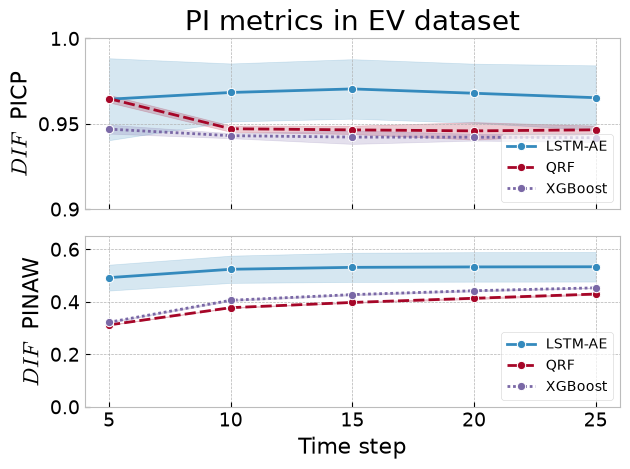

In [6]:
fig, (ax1, ax2) = plt.subplots(nrows=2, sharex=True)

sns.lineplot(
    data=df\
        [df['Dataset'] == 'ev']\
        [df['Metric'] == 'picp'],
    x='time_step',
    y='dif',
    hue='Architecture',
    markers='o',
    errorbar=('se', 3),
    style='Architecture',
    ax=ax1
)

sns.lineplot(
    data=df\
        [df['Dataset'] == 'ev']\
        [df['Metric'] == 'pinaw'],
    x='time_step',
    y='dif',
    hue='Architecture',
    style='Architecture',
    markers='o',
    errorbar=('se', 3),
    ax=ax2
)

ax1.set_ylabel(r'$DIF\ $ PICP', size=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(loc='lower right', framealpha=0.7)
ax1.set_yticks(ticks=[0.9, 0.95, 1.0], labels=[0.9, 0.95, 1.0])
ax1.set_ylim((0.9, 1.0))

ax2.set_xlabel('Time step', size=16)
ax2.tick_params(axis='both', labelsize=14)
ax2.set_ylabel(r'$DIF\ $ PINAW', size=16)
ax2.legend(loc='lower right', framealpha=0.7)
ax2.set_xticks(ticks=range(5,30,5), labels=range(5,30,5))
ax2.set_ylim((0.0, 0.65))

ax1.set_title('PI metrics in EV dataset', size=20)

plt.tight_layout()
plt.savefig('../images/dataset-ev-metrics.png', dpi=750)

/tmp/ipykernel_141773/2928379786.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/2928379786.py:3: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(
/tmp/ipykernel_141773/2928379786.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/2928379786.py:16: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


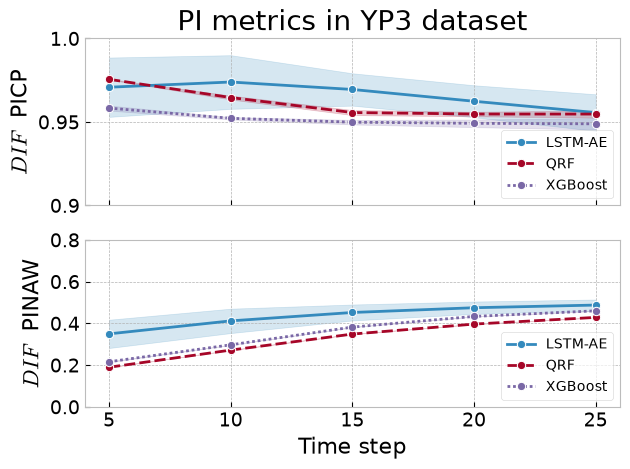

In [7]:
fig, (ax1, ax2) = plt.subplots(nrows=2, sharex=True)

sns.lineplot(
    data=df\
        [df['Dataset'] == 'yp3']\
        [df['Metric'] == 'picp'],
    x='time_step',
    y='dif',
    hue='Architecture',
    markers='o',
    errorbar=('se', 3),
    style='Architecture',
    ax=ax1
)

sns.lineplot(
    data=df\
        [df['Dataset'] == 'yp3']\
        [df['Metric'] == 'pinaw'],
    x='time_step',
    y='dif',
    hue='Architecture',
    style='Architecture',
    markers='o',
    errorbar=('se', 3),
    ax=ax2
)

ax1.set_ylabel(r'$DIF\ $ PICP', size=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(loc='lower right', framealpha=0.7)
ax1.set_yticks(ticks=[0.9, 0.95, 1.0], labels=[0.9, 0.95, 1.0])
ax1.set_ylim((0.9, 1.0))

ax2.set_xlabel('Time step', size=16)
ax2.tick_params(axis='both', labelsize=14)
ax2.set_ylabel(r'$DIF\ $ PINAW', size=16)
ax2.legend(loc='lower right', framealpha=0.7)
ax2.set_xticks(ticks=range(5,30,5), labels=range(5,30,5))
ax2.set_ylim((0.0, 0.8))

ax1.set_title('PI metrics in YP3 dataset', size=20)

plt.tight_layout()
plt.savefig('../images/dataset-yp3-metrics.png', dpi=750)

/tmp/ipykernel_141773/2183994271.py:13: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/2183994271.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[0].set_xticklabels(['Loss lower bound', 'Loss upper bound'], size=16)
/tmp/ipykernel_141773/2183994271.py:57: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/2183994271.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[1].set_xticklabels(['Loss lower bound', 'Loss upper bound'], size=16)


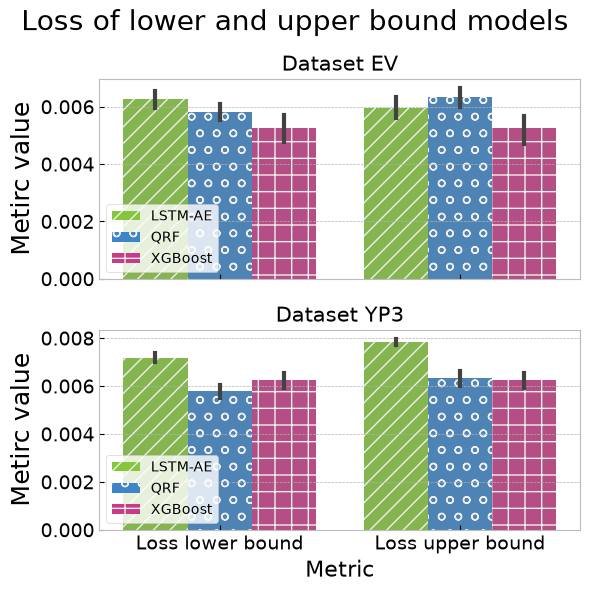

In [64]:
# Parts of code from https://github.com/mwaskom/seaborn/issues/1456#issuecomment-399002203:

from itertools import cycle
fig, axs = plt.subplots(nrows=2, figsize=(6,6), sharex=True)
fig.suptitle('Loss of lower and upper bound models', size=20)

hatches = ['//', 'o', '+']
hatches_cycle = cycle(hatches)
colors = ['#85c63d','#3d85c6',"#c63d85",]


sns.barplot(
    data=df\
        [df['Dataset'] == 'yp3']\
        [(df['Metric'] == 'loss_low') | (df['Metric'] == 'loss_high')],
    x='Metric',
    y='dif',
    hue='Architecture',
    errorbar=("ci", 95),
    ax=axs[0],
    palette=sns.color_palette(colors)
)
num_locations = 2
for i, patch in enumerate(axs[0].patches):
    if i % num_locations == 0:
        hatch = next(hatches_cycle)
    patch.set_hatch(hatch)


# Source - https://stackoverflow.com/a/44937210
# Posted by Andras Deak -- Слава Україні
# Retrieved 2026-09-25, License - CC BY-SA 3.0

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


circ1 = mpatches.Patch( facecolor=colors[0],hatch=hatches[0],label='LSTM-AE')
circ2= mpatches.Patch( facecolor=colors[1],hatch=hatches[1],label='QRF')
circ3 = mpatches.Patch(facecolor=colors[2],hatch=hatches[2],label='XGBoost')

axs[0].legend(handles = [circ1,circ2,circ3])
plt.tight_layout()

axs[0].set_xticklabels(['Loss lower bound', 'Loss upper bound'], size=16)
axs[0].set_ylabel('$DIF$', size=18)
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_xlabel('')
axs[0].set_title('Dataset EV', size=15)

hatches = ['//', 'o', '+']
hatches_cycle = cycle(hatches)
colors = ['#85c63d','#3d85c6',"#c63d85",]


sns.barplot(
    data=df\
        [df['Dataset'] == 'ev']\
        [(df['Metric'] == 'loss_low') | (df['Metric'] == 'loss_high')],
    x='Metric',
    y='dif',
    hue='Architecture',
    errorbar=("ci", 95),
    ax=axs[1],
    palette=sns.color_palette(colors)
)
num_locations = 2
for i, patch in enumerate(axs[1].patches):
    if i % num_locations == 0:
        hatch = next(hatches_cycle)
    patch.set_hatch(hatch)


# Source - https://stackoverflow.com/a/44937210
# Posted by Andras Deak -- Слава Україні
# Retrieved 2026-09-25, License - CC BY-SA 3.0

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


circ1 = mpatches.Patch( facecolor=colors[0],hatch=hatches[0],label='LSTM-AE')
circ2= mpatches.Patch( facecolor=colors[1],hatch=hatches[1],label='QRF')
circ3 = mpatches.Patch(facecolor=colors[2],hatch=hatches[2],label='XGBoost')

axs[1].legend(handles = [circ1,circ2,circ3])
plt.tight_layout()

axs[1].set_xticklabels(['Loss lower bound', 'Loss upper bound'], size=16)
axs[0].set_ylabel('Metirc value', size=18)
axs[1].set_ylabel('Metirc value', size=18)
axs[1].tick_params(axis='both', labelsize=14)
axs[1].set_xlabel('Metric', size=16)
axs[1].set_title('Dataset YP3', size=15)

plt.tight_layout()
plt.savefig('loss-ev-yp3.png', dpi=750)
plt.show()


/tmp/ipykernel_141773/2076307010.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=df\
/tmp/ipykernel_141773/2076307010.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs.set_xticklabels(['Loss lower bound', 'Loss upper bound'], size=16)


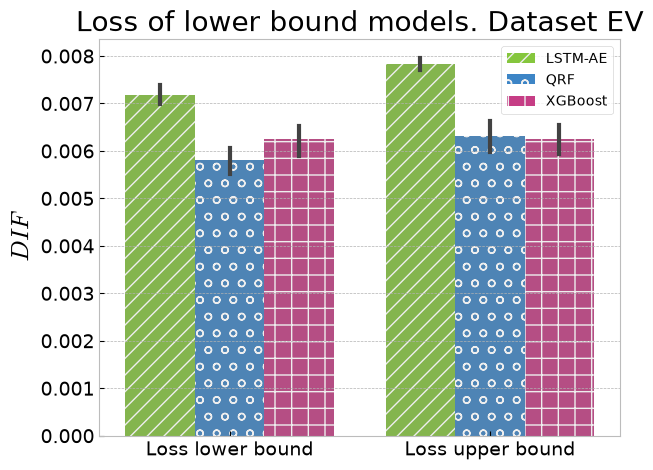